Shumo Wang 25/06/2026

This code uses several libraries to analyze pressure readings from different OSR settings. Histograms and line charts can be plotted. The code also includes a analysis of relationship of STD and charge consumed with OSR.

Most amount of code is the same with NORMALMODE_Analysis.ipynb

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from scipy.optimize import curve_fit

In [80]:
with open("BMP581_OSR64x.txt", "r") as f:
    data = f.readlines()
data = data[2:]
Pressures = [float(i.strip()[-10:]) for i in data]

df = pd.DataFrame({"Time":[i*0.01 for i in range(len(Pressures))], "Pressure": Pressures})
df

,Time,Pressure
0,0.00,100947.34
1,0.01,100947.22
2,0.02,100947.25
3,0.03,100947.13
4,0.04,100947.02
...,...,...
496,4.96,100947.78
497,4.97,100947.92
498,4.98,100947.59
499,4.99,100947.69


In [81]:
window = 50 # 50 datas

df["rolling_mean"] = (
    df["Pressure"]
    .rolling(window=window, center=True)
    .mean() # calculate the mean of 50 datas
)

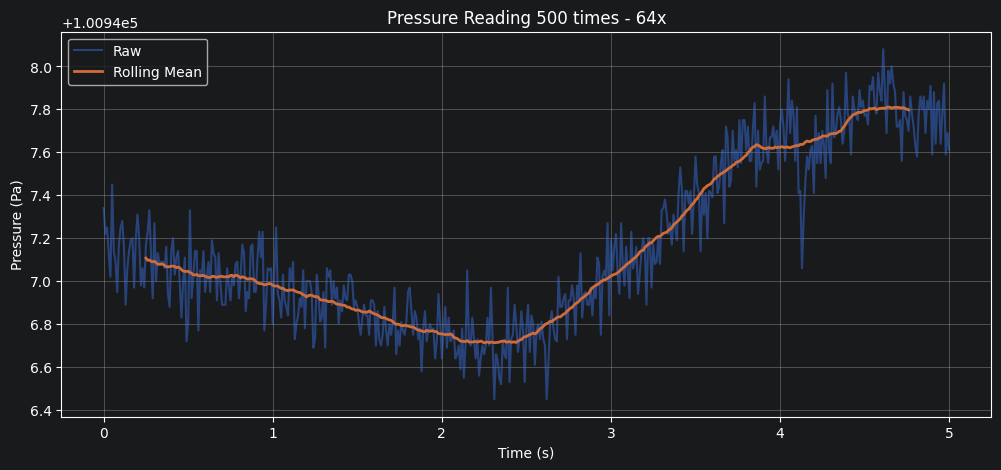

In [82]:
plt.figure(figsize=(12,5))
plt.plot(df["Time"], df["Pressure"], alpha=0.5, label="Raw")
plt.plot(df["Time"], df["rolling_mean"], linewidth=2, label="Rolling Mean")
plt.xlabel("Time (s)")
plt.ylabel("Pressure (Pa)")
plt.title("Pressure Reading 500 times - 64x")
plt.grid(True)
plt.legend()
plt.show()

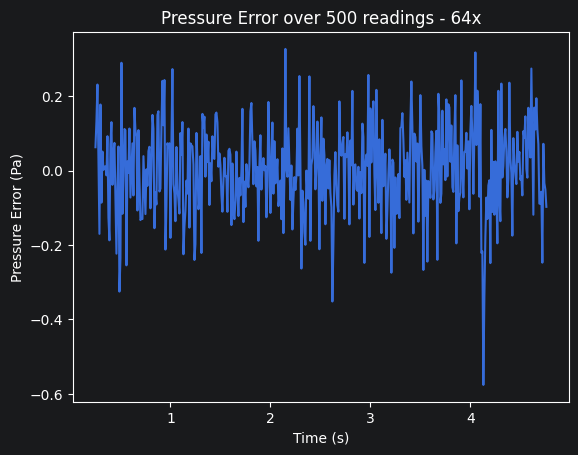

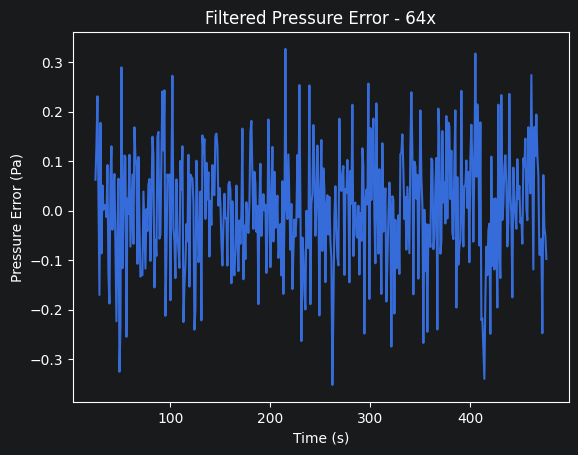

In [83]:
error = df["Pressure"] - df["rolling_mean"]

plt.plot(df["Time"], error, label="Pressure")
plt.xlabel("Time (s)")
plt.ylabel("Pressure Error (Pa)")
plt.title("Pressure Error over 500 readings - 64x")
plt.show()

# A filter to remove data larger than three times std.
mu = np.mean(error)
sigma = np.std(error)

filtered = error[(error > mu-3*sigma) &
                 (error < mu+3*sigma)]

plt.plot(filtered, label="Pressure")
plt.xlabel("Time (s)")
plt.ylabel("Pressure Error (Pa)")
plt.title("Filtered Pressure Error - 64x")
plt.show()

-0.0046093333333717765
0.13755619156180132
0.7972000000008848


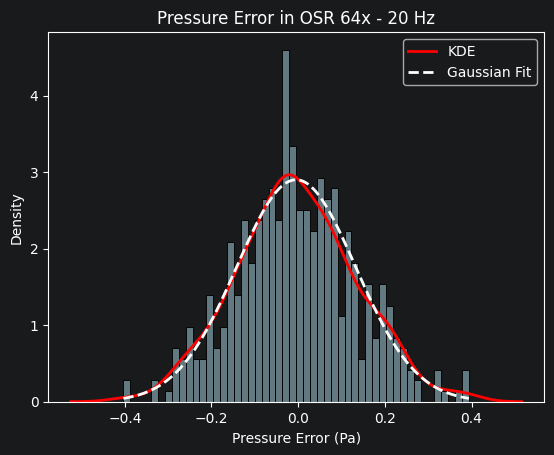

In [56]:
data = filtered.dropna()

mu = data.mean()
sigma = data.std()
print(mu)
print(sigma)
print(data.max() - data.min())

x = np.linspace(data.min(), data.max(), 1000)

sns.histplot(data, bins=50, stat="density",
             color="lightblue", alpha=0.5)

sns.kdeplot(data,
            color="red",
            linewidth=2,
            label="KDE")

plt.plot(x,
         norm.pdf(x, mu, sigma),
         color="white",
         linestyle="--",
         linewidth=2,
         label="Gaussian Fit")

plt.legend()
plt.title("Pressure Error in OSR 64x - 20 Hz")
plt.xlabel("Pressure Error (Pa)")
plt.show()

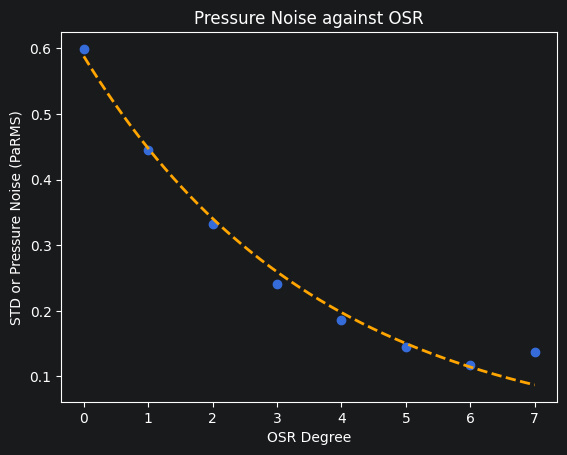

In [79]:
STD = np.array([0.599, 0.445, 0.333, 0.241, 0.186, 0.145, 0.118, 0.138])
OSR = np.array([0, 1, 2, 3, 4, 5, 6, 7])

# define an exponential function
def exp_func(x, a, b):
    return a * np.exp(b * x)

# draw a exponential line of best fit
popt, pcov = curve_fit(exp_func, OSR, STD)
x = np.linspace(OSR.min(), OSR.max(), 1000)
y = exp_func(x, *popt)

plt.scatter(OSR, STD)
plt.xlabel("OSR Degree")
plt.ylabel("STD or Pressure Noise (PaRMS)")
plt.title("Pressure Noise against OSR")
plt.plot(x, y, color="orange", linestyle="--", linewidth=2)
plt.show()

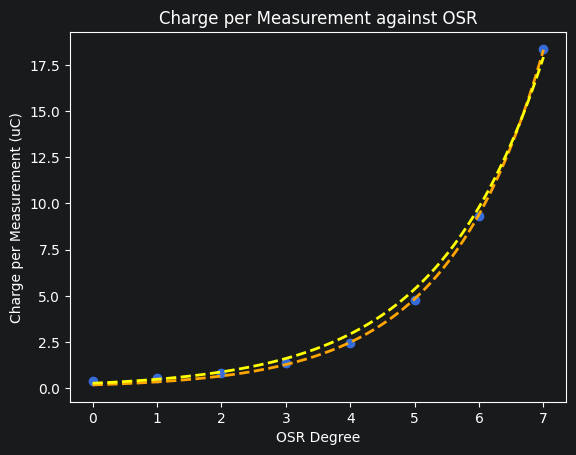

In [16]:
# Same method applied to charge consumed
Charge = np.array([0.39, 0.53, 0.8, 1.36, 2.46, 4.78, 9.32, 18.37])
OSR = np.array([0, 1, 2, 3, 4, 5, 6, 7])

def exp_func(x, a, b):
    return a * np.exp(b * x)

popt, pcov = curve_fit(exp_func, OSR, Charge)
x = np.linspace(OSR.min(), OSR.max(), 1000)
y = exp_func(x, *popt)

plt.scatter(OSR, Charge)
plt.xlabel("OSR Degree")
plt.ylabel("Charge per Measurement (uC)")
plt.title("Charge per Measurement against OSR")
plt.plot(x, y, color="orange", linestyle="--", linewidth=2)


def cost_func(y_hat, y):
    m = len(y)
    return np.sum(((y_hat - y) ** 2) / m / 2)

a = 0.5
b = 0.4
learning_rate = 0.0001
y_hat = exp_func(OSR, a, b)

cost = cost_func(y_hat, Charge)
prev_cost = 0

while abs(cost - prev_cost) >= 0.0001:
    next_a = a - learning_rate * np.sum((y_hat - Charge) * exp_func(OSR, 1, b) / len(OSR))
    next_b = b - learning_rate * np.sum((y_hat - Charge) * a * (OSR * np.exp(b * OSR)) / len(OSR))
    a = next_a
    b = next_b
    prev_cost = cost
    cost = cost_func(exp_func(OSR, a, b), Charge)
    y_hat = exp_func(OSR, a, b)

plt.plot(x, exp_func(x, a, b), color="yellow", linestyle="--", linewidth=2)
plt.show()